聚类算法

1. k-mean 简单的聚类算法，选取固定初始质心，求每个元素到质心的欧几里得距离，最小者分到对应质心的簇，有几个质心就有几个簇(初始质心选择不好，会出现有些簇为空，也就是聚类个数不够)。k-mean++的实现是常用的，选出一个质心，计算每个样本到质心的距离Di，使用概率 获取下一个质心

2. 层次聚类

3. DBSCAN： 如果一个点周围足够多的邻居，它们就属于同一类，ε (epsilon)：邻居的搜索半径（多远的距离算"附近"），minPts：最少需要多少个邻居才算"密集"

4. GMM



DBSCAN

基于密度的聚类，将高密度区域连成簇，对参数epsilon和min_samples敏感。DBSCAN不需要指定类别数，自动发现,计算效率更高，适合大数据量（16000个点）

In [ ]:
from sklearn.cluster import DBSCAN
model = DBSCAN(eps=0.5, min_samples=5)
labels = model.fit_predict(X)

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# %% 1. 模型网格初始化
nx, nz = 160, 100
dx, dz = 0.1, 0.1
x = np.linspace(0, (nx-1)*dx, nx)
z = np.linspace(0, (nz-1)*dz, nz)
X, Z = np.meshgrid(x, z)

#   曲线型水文背景场（随深度呈指数衰减）
Eps_bg = 4.0 + 18.0 * np.exp(-0.8 * Z) # 介电常数
Sigma_bg = 0.005 + 0.045 * np.exp(-0.6 * Z) # 电导率
np.random.seed(101)
eps_noise = 0.25 * np.random.randn(nz, nx)
sig_noise = 0.002 * np.random.randn(nz, nx)
Eps_model = Eps_bg + eps_noise
Sigma_model = Sigma_bg + sig_noise


# 初始化真实类别标签矩阵 (1: 背景, 2: 空洞点, 3: 富水点)
True_Labels = np.ones([nz, nx])
#添加两个"点状型"异常体（含轻微内部扰动）
p1_center = [5.0, 3.0]
r1 = 0.25  # 异常1：空洞点 (低介电、低电导)
p2_center = [11.0, 6.5]
r2 = 0.3   # 异常2：富水点 (高介电、高电导)

for i in range(nz):
    for j in range(nx):
        d1 = np.sqrt((X[i,j] - p1_center[0])**2 + (Z[i,j] - p1_center[1])**2)
        d2 = np.sqrt((X[i,j] - p2_center[0])**2 + (Z[i,j] - p2_center[1])**2)
        if d1 <= r1:
            # 空洞点（添加轻微扰动模拟内壁不规则性）
            Eps_model[i,j] = 1.2 + 0.1 * np.random.randn()
            Sigma_model[i,j] = 0.0002 + 0.00005 * np.random.randn()
            True_Labels[i,j] = 2
        elif d2 <= r2:
            # 富水点（添加轻微扰动模拟水分富集差异）
            Eps_model[i,j] = 45.0 + 1.5 * np.random.randn()
            Sigma_model[i,j] = 0.250 + 0.01 * np.random.randn()
            True_Labels[i,j] = 3

# %% 5. 提取特征并执行 DBSCAN 密度聚类
Eps_col = Eps_model.flatten()
Sig_col = Sigma_model.flatten()
features = np.column_stack([Eps_col, Sig_col])

# 特征标准化 ： 
# scaler = StandardScaler()
# features_norm = scaler.fit_transform(features)

# 0.25-0.5 10-25
db = DBSCAN(eps=0.5, min_samples=5)
cluster_idx = db.fit_predict(features)

# 处理聚类标签：将所有标签+1，使背景从0变成1，噪声(-1)变成0
Cluster_Labels = cluster_idx.copy()
# 首先将噪声(-1)单独处理
noise_mask = Cluster_Labels == -1
# 其他标签加1
Cluster_Labels[~noise_mask] = Cluster_Labels[~noise_mask] + 1
# 噪声设为0
Cluster_Labels[noise_mask] = 0


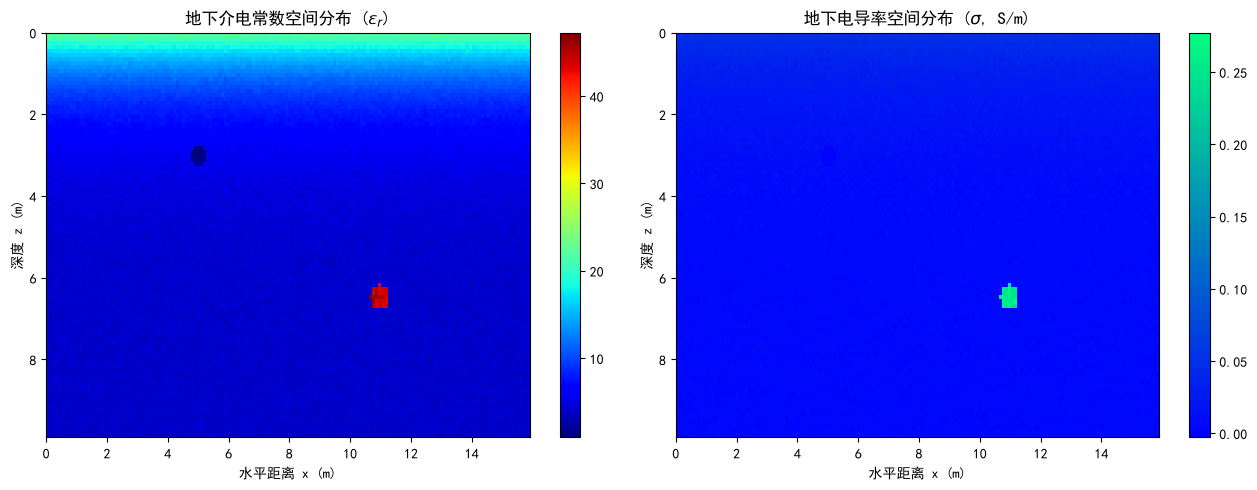

In [4]:

# --- 图表一：地下空间介电常数与电导率二维分布剖面图 ---
fig1, axes = plt.subplots(1, 2, figsize=(13, 5))
fig1.canvas.manager.set_window_title('GPR Spatial Distribution')

im1 = axes[0].imshow(Eps_model, extent=[x.min(), x.max(), z.max(), z.min()], 
                     cmap='jet', aspect='auto')
plt.colorbar(im1, ax=axes[0])
axes[0].set_title(r'地下介电常数空间分布 ($\epsilon_r$)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('水平距离 x (m)', fontsize=10)
axes[0].set_ylabel('深度 z (m)', fontsize=10)

im2 = axes[1].imshow(Sigma_model, extent=[x.min(), x.max(), z.max(), z.min()], 
                     cmap='winter', aspect='auto')
plt.colorbar(im2, ax=axes[1])
axes[1].set_title(r'地下电导率空间分布 ($\sigma$, S/m)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('水平距离 x (m)', fontsize=10)
axes[1].set_ylabel('深度 z (m)', fontsize=10)

plt.tight_layout()
plt.savefig('gpr_spatial_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


DBSCAN聚类得到的标签: [0 1 2 3 4]


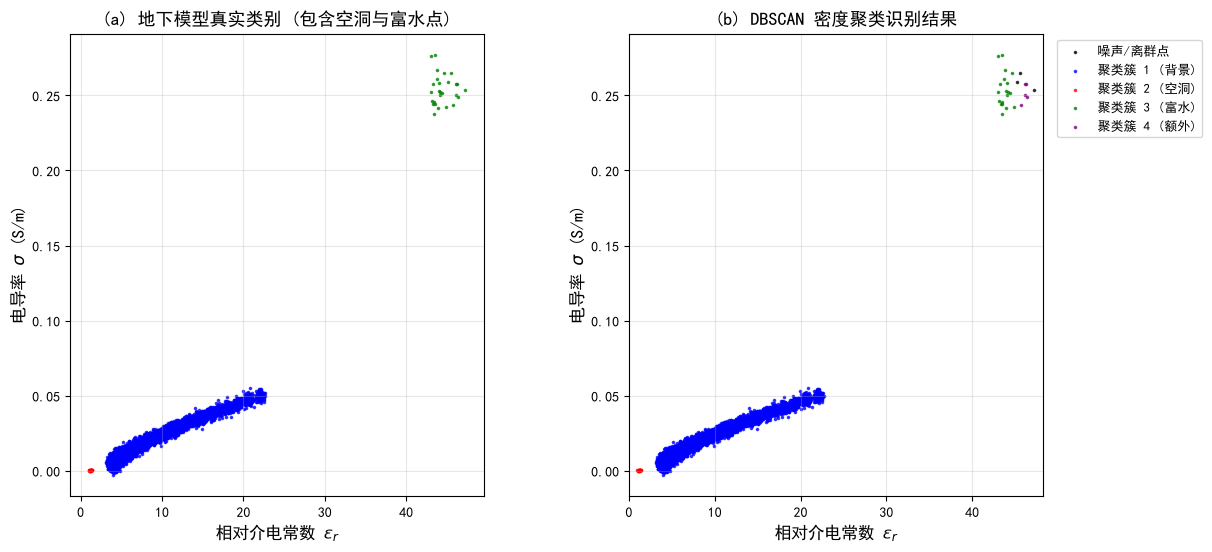

In [19]:
# 图表二：真实类别 和 DBSCAN 聚类结果
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
fig2.canvas.manager.set_window_title('DBSCAN vs Ground Truth')

# 颜色和标记定义
colors_gt = {1: 'blue', 2: 'red', 3: 'green'}
labels_gt = {1: '水文曲线背景 (Class 1)', 2: '空洞点异常 (Class 2)', 3: '富水点异常 (Class 3)'}

# 子图 1：真实类别 (Ground Truth)
for label_val in [1, 2, 3]:
    mask = True_Labels.flatten() == label_val
    axes2[0].scatter(Eps_col[mask], Sig_col[mask], c=colors_gt[label_val], 
                    marker='.', s=10, label=labels_gt[label_val], alpha=0.7)

axes2[0].grid(True, alpha=0.3)
axes2[0].set_xlabel(r'相对介电常数 $\epsilon_r$', fontsize=12, fontweight='bold')
axes2[0].set_ylabel(r'电导率 $\sigma$ (S/m)', fontsize=12, fontweight='bold')
axes2[0].set_title('(a) 地下模型真实类别 (包含空洞与富水点)', fontsize=13, fontweight='bold')
axes2[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
axes2[1].set_xlim([Eps_col.min()-1, Eps_col.max()+1])
plt.subplots_adjust(right=0.82, wspace=0.35)

# 子图 2：DBSCAN 聚类识别结果
# 使用更丰富的颜色列表和动态标签分配
color_list = ['black', 'blue', 'red', 'green', 'purple', 'orange', 'cyan', 'magenta']
default_labels = {
    0: '噪声/离群点',
    1: '聚类簇 1 (背景)',
    2: '聚类簇 2 (空洞)',
    3: '聚类簇 3 (富水)'
}

unique_labels = np.unique(Cluster_Labels)
print(f"DBSCAN聚类得到的标签: {unique_labels}")

for label_val in unique_labels:
    mask = Cluster_Labels == label_val
    
    # 动态获取颜色（如果标签超出预定义范围，使用取模）
    color_idx = min(label_val, len(color_list) - 1)
    c = color_list[color_idx]
    
    # 动态获取标签名称
    if label_val in default_labels:
        label_text = default_labels[label_val]
    else:
        label_text = f'聚类簇 {label_val} (额外)'
    
    axes2[1].scatter(Eps_col[mask], Sig_col[mask], 
                    c=c, marker='.', s=10, 
                    label=label_text, alpha=0.7)

axes2[1].grid(True, alpha=0.3)
axes2[1].set_xlabel(r'相对介电常数 $\epsilon_r$', fontsize=12, fontweight='bold')
axes2[1].set_ylabel(r'电导率 $\sigma$ (S/m)', fontsize=12, fontweight='bold')
axes2[1].set_title('(b) DBSCAN 密度聚类识别结果', fontsize=13, fontweight='bold')
axes2[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
axes2[1].set_xlim([Eps_col.min()-1, Eps_col.max()+1])
plt.subplots_adjust(right=0.82, wspace=0.35)

plt.savefig('gpr_dbscan_vs_ground_truth.png', dpi=150, bbox_inches='tight')
plt.show()